# CA6003 Bank Marketing — A+B+C+D

**Research question:** How do special-value semantics and unknown-information handling affect predictive reliability?

| Role | Member | Responsibility |
| --- | --- | --- |
| A | Yu Qiushi | Data provenance, governance and frozen partitions |
| B | Chen Junyu | Training-only EDA and preparation rationale |
| C | Sun Shaojie | Semantic transformation and preprocessing pipelines |
| D | Liang Shuang | Controlled experiments and evaluation |

This Notebook contains the data audit, cleaning decisions, EDA, four controlled ML experiments, results and limitations. Core analysis code is inline. Keep `BankMarketing_Data.zip` in the same directory as this Notebook and launch the kernel from that directory. Run All checks and extracts this companion archive into a temporary directory, reproduces training analyses and validation fits, and recomputes final-test metrics from the previously frozen predictions. It does not refit final-test models or select strategies using test results. No repository clone is required; both files are required for reproduction.

The final test was already executed with the task owner's authorization. Personal review by all four members, video recording and course submission remain pending.

## Reproducible environment

Use Python 3.12 (verified with 3.12.12). In a dedicated environment, install the packages below before selecting its Jupyter kernel. Installation is an explicit setup step, never run automatically by this Notebook.

```bash
python -m pip install numpy==2.5.4 pandas==3.0.6 scipy==1.18.1 scikit-learn==1.8.0 matplotlib==3.11.2 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.4.0
python -m ipykernel install --user --name bank-marketing --display-name "Bank Marketing (Python 3.12)"
```

Use an existing Jupyter front end or VS Code, select this kernel and run all cells in order. The companion archive includes `requirements.current.txt` and `requirements.D.lock.txt` for the full dependency lock; they are available under `ROOT` after the bootstrap cell runs. Runtime versions are printed below. Different numerical-library versions can fail the strict reference checks; use the pinned environment instead of silently relaxing tolerances.

The next short cell loads the companion data archive using the standard library. All substantive analysis and ML code remains visible in the following sections. Temporary files are confined to a newly created directory and do not overwrite local project files.

In [1]:
# Portable, immutable input snapshot (data, split, provenance and evaluation evidence).
# Original evidence bytes are preserved for hash verification, not imported as executable code.
import hashlib, io, tempfile, zipfile
from pathlib import Path, PurePosixPath
_data_file = Path('BankMarketing_Data.zip')
assert _data_file.is_file(), 'Place BankMarketing_Data.zip beside this notebook and run from that directory'
_payload = _data_file.read_bytes()
assert hashlib.sha256(_payload).hexdigest() == '976e9268ddb389facd26113c2f76c2aee8643ff2b31330e8dc592620fcd41f68', 'Companion archive hash mismatch'
_workspace = tempfile.TemporaryDirectory(prefix='bank_marketing_')
ROOT = Path(_workspace.name)
with zipfile.ZipFile(io.BytesIO(_payload)) as _archive:
    for _entry in _archive.infolist():
        _relative = PurePosixPath(_entry.filename)
        assert not _relative.is_absolute() and '..' not in _relative.parts
        _target = ROOT.joinpath(*_relative.parts)
        _target.parent.mkdir(parents=True, exist_ok=True)
        _target.write_bytes(_archive.read(_entry))
print('Companion data archive loaded and SHA-256 verified.')
del _payload


Companion data archive loaded and SHA-256 verified.


In [2]:
from pathlib import Path
import sys, json, platform
assert (ROOT / 'data/raw/bank-full.csv').is_file(), 'Run the bootstrap cell first'
import sklearn, pandas as pd, numpy as np
print({'python': platform.python_version(), 'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__})

{'python': '3.12.12', 'sklearn': '1.8.0', 'pandas': '3.0.6', 'numpy': '2.5.4'}


In [3]:
from IPython.display import display

## 01–02 / A: Data provenance, scope and quality governance

In [4]:
"""Frozen data contract shared by A/B/C/D. No learned transformations."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

LOCK = json.loads((ROOT / "config/dataset_lock.json").read_text(encoding="utf-8"))
EXPECTED_COLUMNS = LOCK["columns"]
FEATURES = LOCK["allowed_features"]
EXCLUDED = LOCK["excluded_features"]
NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORIES = {
    "job": ["admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services"],
    "marital": ["married", "divorced", "single"],
    "education": ["unknown", "secondary", "primary", "tertiary"],
    "default": ["yes", "no"], "housing": ["yes", "no"], "loan": ["yes", "no"],
    "contact": ["unknown", "telephone", "cellular"],
    "month": ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "poutcome": ["unknown", "other", "failure", "success"], "y": ["yes", "no"],
}


def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def verify_bytes(data: bytes, expected: dict, label: str) -> None:
    if sha256_bytes(data) != expected["sha256"]:
        raise ValueError(f"SHA-256 mismatch: {label}. Do not repair or overwrite the raw file.")
    if "bytes" in expected and len(data) != expected["bytes"]:
        raise ValueError(f"Byte length mismatch: {label}")


def read_raw(root: Path = ROOT) -> pd.DataFrame:
    path = root / "data/raw/bank-full.csv"
    verify_bytes(path.read_bytes(), LOCK["artifacts"]["data/raw/bank-full.csv"], str(path.name))
    raw = pd.read_csv(path, sep=";", keep_default_na=False)
    if list(raw.columns) != EXPECTED_COLUMNS or raw.shape != (45211, 17):
        raise ValueError("Unexpected CSV version, columns, or shape")
    for column in NUMERIC:
        if not pd.api.types.is_integer_dtype(raw[column]):
            raise ValueError(f"Expected integer dtype: {column}")
    for column, allowed in CATEGORIES.items():
        if not raw[column].isin(allowed).all():
            raise ValueError(f"Unexpected category: {column}")
    if raw.isna().any().any() or raw.astype(str).apply(lambda s: s.str.strip().eq("")).any().any():
        raise ValueError("Unexpected actual missing/empty cell")
    raw.index.name = "row_id"  # Original zero-based data-record position, not CSV line number.
    return raw


def make_splits(raw: pd.DataFrame) -> dict[str, np.ndarray]:
    y = raw["y"].map({"no": 0, "yes": 1})
    if y.isna().any():
        raise ValueError("Unexpected target value")
    ids = np.arange(len(raw))
    dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
    train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
    return {"train": train, "val": val, "test": test}


def make_manifest(raw: pd.DataFrame, splits: dict[str, np.ndarray]) -> pd.DataFrame:
    assignment = pd.Series("", index=np.arange(len(raw)), name="split")
    for name, ids in splits.items():
        assignment.loc[ids] = name
    result = assignment.rename_axis("row_id").reset_index()
    all_ids = np.concatenate(list(splits.values()))
    if len(all_ids) != len(raw) or len(np.unique(all_ids)) != len(raw):
        raise ValueError("Splits overlap or fail complete coverage")
    if not np.array_equal(np.sort(all_ids), np.arange(len(raw))) or assignment.eq("").any():
        raise ValueError("Invalid split row ids")
    return result


def load_split_indices(root: Path = ROOT) -> dict[str, np.ndarray]:
    saved = json.loads((root / "data/splits/split_indices.json").read_text(encoding="utf-8"))
    if not isinstance(saved, dict) or set(saved) != {"train", "val", "test"}:
        raise ValueError("Unexpected split names")
    for name, ids in saved.items():
        if not isinstance(ids, list) or any(type(value) is not int for value in ids):
            raise ValueError(f"Split {name} row ids must be plain JSON integers; no strings, floats or booleans")
        if any(value < 0 or value >= LOCK["shape"][0] for value in ids):
            raise ValueError(f"Split {name} row id outside original row range")
    return {name: np.asarray(ids, dtype=np.int64) for name, ids in saved.items()}


def validate_saved_splits(raw: pd.DataFrame, root: Path = ROOT) -> dict[str, np.ndarray]:
    expected = make_splits(raw)
    saved = load_split_indices(root)
    for name in expected:
        if not np.array_equal(saved[name], expected[name]):
            raise ValueError(f"Frozen split changed: {name}")
    manifest = pd.read_csv(root / "data/splits/split_manifest.csv", keep_default_na=False)
    pd.testing.assert_frame_equal(manifest, make_manifest(raw, expected))
    return saved


def load_partition(name: str, *, allow_test: bool = False, root: Path = ROOT):
    """Return X (11 original columns), integer y, with aligned row_id indices.

    The flag is a workflow guard, not access control: raw data remain available.
    C/D must preserve this row order and fit learned transforms only on training.
    """
    if name not in {"train", "val", "test"}:
        raise ValueError("Expected train, val, or test")
    if name == "test" and not allow_test:
        raise ValueError("Test is sealed until protocol freeze; D must explicitly allow_test=True")
    raw = read_raw(root)
    splits = validate_saved_splits(raw, root)
    frame = raw.loc[splits[name]]
    X = frame.loc[:, FEATURES].copy()
    y = frame["y"].map({"no": 0, "yes": 1}).astype("int64")
    if not X.index.equals(y.index) or list(X.columns) != FEATURES:
        raise ValueError("Broken model-input contract")
    return X, y


## 1. Provenance, license and scope

We use only legacy `bank-full.csv`: 45,211 rows, 16 original inputs and target `y`. Provenance follows the outer ZIP, nested `bank.zip`, and original CSV/documentation. The additional dataset, sampled `bank.csv`, and reformatted `data.csv` are excluded.

Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), by Moro, Rita and Cortez; [DOI 10.24432/C5K306](https://doi.org/10.24432/C5K306). License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The legacy documentation also credits Moro, Laureano and Cortez (2011), *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology*. Full attribution is included in `THIRD_PARTY_NOTICES.md` in the companion archive.

Raw bytes remain unchanged. Row identifiers, splits and audits are project derivatives. Attribution does not imply endorsement by the authors or UCI. All required inputs are restored from the companion archive; no personal file paths or online downloads are used.

In [5]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
assert (ROOT / 'config/dataset_lock.json').is_file(), 'Run the bootstrap cell first'
lock = json.loads((ROOT / 'config/dataset_lock.json').read_text(encoding='utf-8'))
for relative, expected in lock['artifacts'].items():
    data = (ROOT / relative).read_bytes()
    assert hashlib.sha256(data).hexdigest() == expected['sha256'], relative
    assert 'bytes' not in expected or len(data) == expected['bytes'], relative
provenance = json.loads((ROOT / 'data/source/provenance.json').read_text(encoding='utf-8'))
print('Acquired UTC:', provenance['acquired_utc'])
print('Raw SHA-256:', lock['artifacts']['data/raw/bank-full.csv']['sha256'])
print('All four pinned source artifacts verified')

Acquired UTC: 2026-10-12T09:30:28.154035+00:00
Raw SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d
All four pinned source artifacts verified


## 2. Read without semantic cleaning and freeze the exact split

`keep_default_na=False` preserves literal `unknown` and empty strings; actual missing values are checked separately. `row_id=np.arange(len(raw))` is the zero-based original row position, not a customer identifier or predictor. Both stratified splits use `random_state=42`; the second stratifies on `y.iloc[dev]`. The manifest is sorted by original row ID, while the JSON preserves the order returned by the split operations.

In [6]:
raw = pd.read_csv(ROOT / 'data/raw/bank-full.csv', sep=';', keep_default_na=False)
assert list(raw.columns) == lock['columns'] and raw.shape == (45211, 17)
y = raw['y'].map({'no': 0, 'yes': 1})
assert not y.isna().any()
ids = np.arange(len(raw))
dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
splits = {'train': train, 'val': val, 'test': test}
assert len(set(train) & set(val)) == 0
assert len(set(dev) & set(test)) == 0
assert set(np.concatenate(list(splits.values()))) == set(ids)
assignment = pd.Series('', index=ids, name='split')
for name, positions in splits.items():
    assignment.loc[positions] = name
manifest = assignment.rename_axis('row_id').reset_index()
pd.testing.assert_frame_equal(manifest, pd.read_csv(ROOT / 'data/splits/split_manifest.csv'))
saved = json.loads((ROOT / 'data/splits/split_indices.json').read_text(encoding='utf-8'))
assert all(np.array_equal(splits[name], saved[name]) for name in splits)
raw.index.name = 'row_id'
print('Shape:', raw.shape, 'split sizes:', {k: len(v) for k,v in splits.items()})

Shape: (45211, 17) split sizes: {'train': 27126, 'val': 9042, 'test': 9043}


The following table exposes label distributions only for training. Validation/test rows show predefined coverage and sizes without label statistics at this audit stage. Open-ended profiling uses training only. Sealing is a workflow constraint: the original CSV still contains all records.

In [7]:
display(pd.read_csv(ROOT / 'outputs/split_summary.csv'))
format_checks = pd.read_csv(ROOT / 'outputs/format_checks.csv')
assert format_checks.n_violations.sum() == 0
print('Predeclared holdout format checks passed:', len(format_checks))

,partition,n_rows,n_no,n_yes,positive_rate,purpose
0,train,27126,23953.0,3173.0,0.116973,training profile
1,val,9042,NaN,NaN,NaN,structure/coverage only; label statistics with...
2,test,9043,NaN,NaN,NaN,structure/coverage only; label statistics with...


Predeclared holdout format checks passed: 78


## 3. Dictionary and prediction-time policy

The 11 permitted inputs are `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan`, `pdays`, `previous` and `poutcome`.

`duration` is post-call information. We also exclude `campaign`, `contact`, `day` and `month` under a conservative pre-contact scope. This is our study design, not a UCI or course requirement. Reviewer fields remain pending until actual personal review.

In [8]:
dictionary = pd.read_csv(ROOT / 'notes/data_dictionary.csv', keep_default_na=False)
policy = pd.read_csv(ROOT / 'notes/feature_policy.csv', keep_default_na=False)
assert dictionary.field.tolist() == lock['columns']
allowed = policy.loc[policy.role.eq('input'), 'field'].tolist()
assert allowed == lock['allowed_features']
assert not set(allowed) & {'y', 'row_id', 'duration', 'campaign', 'contact', 'day', 'month'}
display(dictionary)
display(policy[['field', 'role', 'prediction_time', 'reviewer']])

,field,storage_type,meaning,unit,documented_categories,special_semantics,role,source
0,age,integer,Client age,years,,Positive integer; no arbitrary age trimming,input,data/raw/bank-names.txt; UCI dataset 222
1,job,string,Type of job,category,admin.|unknown|unemployed|management|housemaid...,unknown is a literal category; U applies here,input,data/raw/bank-names.txt; UCI dataset 222
2,marital,string,Marital status,category,married|divorced|single,divorced includes divorced or widowed in the s...,input,data/raw/bank-names.txt; UCI dataset 222
3,education,string,Education category,category,unknown|secondary|primary|tertiary,Legacy primary/secondary/tertiary/unknown; U a...,input,data/raw/bank-names.txt; UCI dataset 222
4,default,string,Has credit in default?,yes/no,yes|no,Do not infer default amount or date,input,data/raw/bank-names.txt; UCI dataset 222
5,balance,integer,Average yearly balance,EUR,,Negative and extreme values are not automatica...,input,data/raw/bank-names.txt; UCI dataset 222
6,housing,string,Has housing loan?,yes/no,yes|no,Retain original categories,input,data/raw/bank-names.txt; UCI dataset 222
7,loan,string,Has personal loan?,yes/no,yes|no,Retain original categories,input,data/raw/bank-names.txt; UCI dataset 222
8,contact,string,Last contact communication type,category,unknown|telephone|cellular,Current campaign contact process; excluded,excluded,data/raw/bank-names.txt; UCI dataset 222
9,day,integer,Day of month of last contact,1-31,,Not day_of_week; incomplete calendar information,excluded,data/raw/bank-names.txt; UCI dataset 222


,field,role,prediction_time,reviewer
0,age,input,Assumed available before current campaign cont...,pending
1,job,input,Assumed available before current campaign cont...,pending
2,marital,input,Assumed available before current campaign cont...,pending
3,education,input,Assumed available before current campaign cont...,pending
4,default,input,Assumed available before current campaign cont...,pending
5,balance,input,Assumed available before current campaign cont...,pending
6,housing,input,Assumed available before current campaign cont...,pending
7,loan,input,Assumed available before current campaign cont...,pending
8,contact,excluded,Current/last-contact or campaign process; cons...,pending
9,day,excluded,Current/last-contact or campaign process; cons...,pending


## 4. Training-only quality evidence

The audit functions are included directly below. We distinguish actual NaN/empty strings, literal `unknown`, and the `pdays=-1` sentinel. The sentinel means no previous contact; `pdays=0` is a real interval. Negative balances, large counts and matching records are not automatically errors. A STOP rule blocks processing only when `n_affected>0`; INVESTIGATE requests review without deleting records.

Cleaning is implemented conservatively: validate the whitelist and raw values, encode sentinel semantics in S, handle job/education unknowns in U, and learn imputation/scaling/encoding only inside the current training fit. No unsupported deletion, deduplication or winsorization is applied.

In [9]:
"""Descriptive data-quality evidence. Open profiling is restricted to train."""

import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn



AUDIT_COLUMNS = ["check_id", "field", "rule", "partition", "n_affected", "example_row_ids",
                 "severity", "decision", "rationale", "owner"]


def format_checks(frame: pd.DataFrame, partition: str) -> list[dict]:
    """Rules specified before inspection; holdout checks contain no open profiling."""
    checks = []
    def add(rule, n):
        checks.append({"partition": partition, "rule": rule, "n_violations": int(n), "passed": int(n) == 0})
    add("exact_17_columns_in_source_order", int(list(frame.columns) != EXPECTED_COLUMNS))
    add("no_actual_null_cells", frame.isna().sum().sum())
    add("no_empty_or_whitespace_cells", frame.astype(str).apply(lambda s: s.str.strip().eq("")).sum().sum())
    for column in NUMERIC:
        add(f"{column}:integer_dtype", int(not pd.api.types.is_integer_dtype(frame[column])))
    for column, values in CATEGORIES.items():
        add(f"{column}:documented_category", (~frame[column].isin(values)).sum())
    for name, mask in {
        "age:positive": frame.age.le(0), "day:1_to_31": ~frame.day.between(1, 31),
        "duration:nonnegative": frame.duration.lt(0), "campaign:at_least_one": frame.campaign.lt(1),
        "pdays:minus_one_or_nonnegative": frame.pdays.lt(-1), "previous:nonnegative": frame.previous.lt(0),
    }.items():
        add(name, mask.sum())
    return checks


def profile_train(train: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name in EXPECTED_COLUMNS:
        col = train[name]
        text = col.astype(str)
        item = {"partition": "train", "field": name, "dtype": str(col.dtype), "n_rows": len(col),
                "n_null": int(col.isna().sum()), "n_empty": int(text.eq("").sum()),
                "n_whitespace_only": int((text.str.strip().eq("") & text.ne("")).sum()),
                "n_unknown": int(text.eq("unknown").sum()), "n_minus_one": int(text.eq("-1").sum()),
                "n_unique": int(col.nunique(dropna=False))}
        if name in NUMERIC:
            for label, q in [("min", 0), ("q01", .01), ("q25", .25), ("median", .5), ("q75", .75), ("q99", .99), ("max", 1)]:
                item[label] = float(col.quantile(q))
        rows.append(item)
    return pd.DataFrame(rows)


def audit_train(train: pd.DataFrame) -> pd.DataFrame:
    rows = []
    def add(check_id, field, rule, mask, severity, decision, rationale, owner="A"):
        selected = train.index[np.asarray(mask, dtype=bool)]
        rows.append(dict(zip(AUDIT_COLUMNS, [check_id, field, rule, "train", len(selected),
                    json.dumps([int(x) for x in selected[:5]]), severity, decision, rationale, owner])))
    for name in EXPECTED_COLUMNS:
        values = train[name]
        missing = values.isna() | values.astype(str).str.strip().eq("")
        add("missing_" + name, name, "actual null or empty/whitespace cell", missing, "STOP",
            "Stop if affected; otherwise pass", "Unexpected actual missingness requires source/parse review; no automatic imputation")
        if name in CATEGORIES:
            add("category_" + name, name, "value outside documented bank-names categories", ~values.isin(CATEGORIES[name]), "STOP",
                "Stop if affected; otherwise pass", "Version/format mismatch must be resolved without recoding records")
        unknown = values.astype(str).eq("unknown")
        if "unknown" in CATEGORIES.get(name, []):
            add("unknown_" + name, name, "literal category unknown", unknown, "VALID_STATE", "Retain raw category",
                "Literal unknown is not NaN; C may compare job/education strategies only; poutcome stays unchanged", "A; C implementation pending")
    for name, mask in {
        "age": train.age.le(0), "day": ~train.day.between(1, 31), "duration": train.duration.lt(0),
        "campaign": train.campaign.lt(1), "pdays": train.pdays.lt(-1), "previous": train.previous.lt(0),
    }.items():
        add("domain_" + name, name, "violates predeclared integer domain", mask, "STOP",
            "Stop if affected; otherwise pass", "Verify raw provenance and documentation before any repair")
    add("pdays_never", "pdays", "pdays == -1", train.pdays.eq(-1), "VALID_STATE", "Retain sentinel in raw",
        "Never contacted in a previous campaign; not missing days; S is implemented by C")
    add("pdays_zero", "pdays", "pdays == 0", train.pdays.eq(0), "VALID_STATE", "Retain distinct from -1",
        "Zero elapsed days is a nonnegative interval; it must not mean never contacted")
    add("negative_balance", "balance", "balance < 0", train.balance.lt(0), "VALID_STATE", "Retain negative balance",
        "Average annual balance in EUR can be negative; no evidence of parsing error")
    for name in ["balance", "previous"]:
        cut = float(train[name].quantile(.99))
        add("upper_tail_" + name, name, f"value > training 99th percentile ({cut:g})", train[name].gt(cut), "INVESTIGATE",
            "Retain; B reviews tail evidence", "A descriptive training-only flag, not an invalidity boundary or deletion rule", "A; B review pending")
    never = train.pdays.eq(-1)
    zero_prev = train.previous.eq(0)
    add("history_never_positive_previous", "pdays,previous", "pdays == -1 and previous > 0", never & ~zero_prev, "INVESTIGATE",
        "Retain; review any affected rows", "Different campaign-history definitions may explain a mismatch; do not fabricate contact history", "A; B/C review pending")
    add("history_contacted_zero_previous", "pdays,previous", "pdays >= 0 and previous == 0", ~never & zero_prev, "INVESTIGATE",
        "Retain; review any affected rows", "A semantic consistency check; not grounds for automatic deletion", "A; B/C review pending")
    add("history_contacted_unknown_outcome", "pdays,poutcome", "pdays >= 0 and poutcome == unknown", ~never & train.poutcome.eq("unknown"), "INVESTIGATE",
        "Retain unknown outcome", "Unknown outcome cannot automatically be interpreted as no previous contact", "A; B/C review pending")
    add("history_never_known_outcome", "pdays,poutcome", "pdays == -1 and poutcome != unknown", never & train.poutcome.ne("unknown"), "INVESTIGATE",
        "Retain; verify meaning", "A known outcome alongside never-contacted requires review rather than invented replacement", "A; B/C review pending")
    add("duplicate_full_rows", "all 17 raw fields", "all members of exact duplicate groups (keep=False)", train.duplicated(keep=False), "INVESTIGATE",
        "Retain all rows", "Matching public records do not establish duplicate people; row_id is not customer ID")
    for scope, features in [("raw16", EXPECTED_COLUMNS[:-1]), ("allowed11", FEATURES)]:
        n_labels = train.groupby(features, dropna=False, sort=False)["y"].transform("nunique")
        add("conflicting_labels_" + scope, ",".join(features), "same feature values with more than one target label; affected group members", n_labels.gt(1), "INVESTIGATE",
            "Retain; document identifiability limitation", "Feature equality is not identity; do not merge clients or choose a preferred label")
    return pd.DataFrame(rows, columns=AUDIT_COLUMNS)


def write_reports(raw: pd.DataFrame, splits: dict[str, np.ndarray], root: Path = ROOT) -> dict:
    out = root / "outputs"
    out.mkdir(parents=True, exist_ok=True)
    train = raw.loc[np.sort(splits["train"])]
    profile = profile_train(train)
    audit = audit_train(train)
    profile.to_csv(out / "train_profile.csv", index=False, lineterminator="\n")
    audit.to_csv(out / "quality_audit.csv", index=False, lineterminator="\n")
    formats = pd.DataFrame([check for name, ids in splits.items() for check in format_checks(raw.loc[ids], name)])
    formats.to_csv(out / "format_checks.csv", index=False, lineterminator="\n")
    split_summary = []
    for name, ids in splits.items():
        targets = raw.loc[ids, "y"] if name == "train" else None
        split_summary.append({"partition": name, "n_rows": len(ids),
                              "n_no": int(targets.eq("no").sum()) if targets is not None else None,
                              "n_yes": int(targets.eq("yes").sum()) if targets is not None else None,
                              "positive_rate": float(targets.eq("yes").mean()) if targets is not None else None,
                              "purpose": "training profile" if name == "train" else "structure/coverage only; label statistics withheld"})
    pd.DataFrame(split_summary).to_csv(out / "split_summary.csv", index=False, lineterminator="\n")
    history = train.assign(pdays_state=np.where(train.pdays.eq(-1), "never_-1", "contacted_ge0"),
                           previous_state=np.where(train.previous.eq(0), "zero", "positive"))
    counts = history.groupby(["pdays_state", "previous_state", "poutcome"], dropna=False).size().rename("n").reset_index()
    counts.insert(0, "partition", "train")
    counts["denominator"] = len(train)
    counts.to_csv(out / "train_history_consistency.csv", index=False, lineterminator="\n")
    summary = {
        "raw_shape": list(raw.shape), "split_sizes": {name: len(ids) for name, ids in splits.items()},
        "open_profile_partition": "train", "training_rows": len(train),
        "holdout_policy": "predeclared schema, category membership, numeric domain and row coverage checks only; no holdout label statistics",
        "format_violations": int(formats.n_violations.sum()),
        "audit_stop_affected": int(audit.loc[audit.severity.eq("STOP"), "n_affected"].sum()),
        "training_exact_duplicate_group_members": int(train.duplicated(keep=False).sum()),
        "training_duplicate_excess_rows": int(train.duplicated(keep="first").sum()),
        "training_pdays_minus_one": int(train.pdays.eq(-1).sum()),
        "training_pdays_zero": int(train.pdays.eq(0).sum()),
        "training_unknown_job": int(train.job.eq("unknown").sum()),
        "training_unknown_education": int(train.education.eq("unknown").sum()),
        "training_negative_balance": int(train.balance.lt(0).sum()),
        "rows_deleted": 0, "imputation_fitted": False, "scaler_fitted": False, "models_fitted": 0,
        "student_review": "pending", "C_semantic_review": "pending",
    }
    (out / "audit_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8", newline="\n")
    environment = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                   "scikit-learn": sklearn.__version__, "platform": platform.system(), "machine": platform.machine()}
    (out / "environment.json").write_text(json.dumps(environment, indent=2) + "\n", encoding="utf-8", newline="\n")
    if summary["format_violations"] or summary["audit_stop_affected"]:
        raise ValueError("Blocking data-quality failure; inspect saved audit, do not clean silently")
    return summary


In [10]:

training = raw.loc[np.sort(train)].copy()
profile = profile_train(training)
audit = audit_train(training)
saved_audit = pd.read_csv(ROOT / 'outputs/quality_audit.csv', keep_default_na=False)
pd.testing.assert_frame_equal(audit, saved_audit)
assert audit.partition.eq('train').all()
assert audit.loc[audit.severity.eq('STOP'), 'n_affected'].sum() == 0
display(profile)
display(audit.loc[audit.n_affected.gt(0), ['check_id','field','n_affected','example_row_ids','severity','decision']])
print('No source rows dropped. No imputer/scaler/model fitted.')

,partition,field,dtype,n_rows,n_null,n_empty,n_whitespace_only,n_unknown,n_minus_one,n_unique,min,q01,q25,median,q75,q99,max
0,train,age,int64,27126,0,0,0,0,0,76,18.0,23.0,33.0,39.0,48.00,71.00,95.0
1,train,job,str,27126,0,0,0,179,0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,train,marital,str,27126,0,0,0,0,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train,education,str,27126,0,0,0,1100,0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,train,default,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,train,balance,int64,27126,0,0,0,0,24,5896,-6847.0,-627.0,73.0,454.0,1425.75,13146.25,81204.0
6,train,housing,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,train,loan,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,train,contact,str,27126,0,0,0,7790,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,train,day,int64,27126,0,0,0,0,0,31,1.0,2.0,8.0,16.0,21.00,31.00,31.0


,check_id,field,n_affected,example_row_ids,severity,decision
3,unknown_job,job,179,"[4, 1072, 1292, 2046, 2841]",VALID_STATE,Retain raw category
8,unknown_education,education,1100,"[4, 13, 44, 57, 58]",VALID_STATE,Retain raw category
18,unknown_contact,contact,7790,"[0, 1, 4, 5, 6]",VALID_STATE,Retain raw category
28,unknown_poutcome,poutcome,22240,"[0, 1, 4, 5, 6]",VALID_STATE,Retain raw category
37,pdays_never,pdays,22235,"[0, 1, 4, 5, 6]",VALID_STATE,Retain sentinel in raw
39,negative_balance,balance,2280,"[25, 36, 37, 45, 46]",VALID_STATE,Retain negative balance
40,upper_tail_balance,balance,272,"[446, 2065, 2343, 2778, 2852]",INVESTIGATE,Retain; B reviews tail evidence
41,upper_tail_previous,previous,234,"[24136, 24295, 24331, 24556, 24596]",INVESTIGATE,Retain; B reviews tail evidence
44,history_contacted_unknown_outcome,"pdays,poutcome",5,"[40658, 41821, 42042, 43978, 45021]",INVESTIGATE,Retain unknown outcome
48,conflicting_labels_allowed11,"age,job,marital,education,default,balance,hous...",157,"[269, 378, 523, 787, 931]",INVESTIGATE,Retain; document identifiability limitation


No source rows dropped. No imputer/scaler/model fitted.


## 5. History consistency handoff

Training cross-counts check semantic consistency and guide B's investigation. These observations do not justify inventing contact histories, identifying why an outcome is unknown, or making causal claims. Independent training-only investigation follows.

In [11]:
history = pd.read_csv(ROOT / 'outputs/train_history_consistency.csv')
assert history.partition.eq('train').all() and history.n.sum() == len(training)
display(history)
summary = json.loads((ROOT / 'outputs/audit_summary.json').read_text(encoding='utf-8'))
print(json.dumps(summary, indent=2))

,partition,pdays_state,previous_state,poutcome,n,denominator
0,train,contacted_ge0,positive,failure,2876,27126
1,train,contacted_ge0,positive,other,1117,27126
2,train,contacted_ge0,positive,success,893,27126
3,train,contacted_ge0,positive,unknown,5,27126
4,train,never_-1,zero,unknown,22235,27126


{
  "raw_shape": [
    45211,
    17
  ],
  "split_sizes": {
    "train": 27126,
    "val": 9042,
    "test": 9043
  },
  "open_profile_partition": "train",
  "training_rows": 27126,
  "holdout_policy": "predeclared schema, category membership, numeric domain and row coverage checks only; no holdout label statistics",
  "format_violations": 0,
  "audit_stop_affected": 0,
  "training_exact_duplicate_group_members": 0,
  "training_duplicate_excess_rows": 0,
  "training_pdays_minus_one": 22235,
  "training_pdays_zero": 0,
  "training_unknown_job": 179,
  "training_unknown_education": 1100,
  "training_negative_balance": 2280,
  "rows_deleted": 0,
  "imputation_fitted": false,
  "scaler_fitted": false,
  "models_fitted": 0,
  "student_review": "pending",
  "C_semantic_review": "pending"
}


## 03 / B: Training-only findings and stratified evidence

In [12]:
"""B: descriptive investigation restricted to A's frozen training partition."""
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt




def summarize(frame, keys):
    result = frame.groupby(keys, observed=True, dropna=False)['target'].agg(
        n='size', n_positive='sum').reset_index()
    result['n_negative'] = result.n - result.n_positive
    result['subscription_rate'] = result.n_positive / result.n
    result['small_sample'] = (result.n < 100) | (result.n_positive < 20) | (result.n_negative < 20)
    result['partition'] = 'train'
    return result


def investigate():
    X, y = load_partition('train')
    f = X.copy()
    f['target'] = y
    f['age_group'] = np.where(f.age < 30, '<30', np.where(f.age < 60, '30-59', '>=60'))
    f['history_group'] = np.where(f.pdays < 0, 'never_contacted', 'previously_contacted')
    f['previous_group'] = np.where(f.previous == 0, 'zero', 'positive')
    history = summarize(f, ['history_group', 'previous_group', 'poutcome'])
    history['share_of_train'] = history.n / len(f)
    exceptional = f.loc[(f.pdays.ge(0) & f.poutcome.eq('unknown')) |
                        (f.pdays.ge(0) != f.previous.gt(0))].copy()
    exceptional['reason'] = np.where(exceptional.pdays.ge(0) != exceptional.previous.gt(0),
        'pdays_previous_disagreement', 'contact_recorded_outcome_unknown')
    exceptional['interpretation'] = 'Observed combination; original cause is not identifiable; retain unchanged'

    overview = []
    for label, mask in [('target_yes', y.eq(1)), ('job_unknown', f.job.eq('unknown')),
                        ('education_unknown', f.education.eq('unknown')),
                        ('any_unknown', f.job.eq('unknown') | f.education.eq('unknown')),
                        ('pdays_minus_one', f.pdays.eq(-1)), ('pdays_nonnegative', f.pdays.ge(0))]:
        overview.append(dict(measure=label, n=int(mask.sum()), denominator=len(f),
                             proportion=float(mask.mean()), n_positive=int(y[mask].sum()), partition='train'))
    unknown_tables = []
    for field in ['job', 'education', 'any_unknown']:
        mask = (f.job.eq('unknown') | f.education.eq('unknown')) if field == 'any_unknown' else f[field].eq('unknown')
        for dimension in ['overall', 'age_group', 'history_group']:
            g = f[['target', 'age_group', 'history_group']].copy()
            g['stratum'] = 'all' if dimension == 'overall' else g[dimension]
            g['information'] = np.where(mask, 'unknown', 'known')
            table = summarize(g, ['stratum', 'information'])
            table['field'] = field
            table['dimension'] = dimension
            table['stratum_n'] = table.groupby('stratum').n.transform('sum')
            table['share_in_stratum'] = table.n / table.stratum_n
            unknown_tables.append(table)
    unknown = pd.concat(unknown_tables, ignore_index=True)
    differences = []
    for (field, dimension, stratum), group in unknown.groupby(['field', 'dimension', 'stratum'], sort=False):
        indexed = group.set_index('information')
        if {'unknown', 'known'} <= set(indexed.index):
            differences.append(dict(field=field, dimension=dimension, stratum=stratum,
                unknown_minus_known_pp=100*(indexed.loc['unknown', 'subscription_rate']-indexed.loc['known', 'subscription_rate']),
                unknown_n=int(indexed.loc['unknown','n']), known_n=int(indexed.loc['known','n']),
                small_sample=bool(indexed.small_sample.any()), partition='train'))

    # Direct standardization describes age composition; it is not causal adjustment.
    weights = f.age_group.value_counts(normalize=True)
    standardized = []
    for field in ['job', 'education', 'any_unknown']:
        part = unknown[(unknown.field == field) & (unknown.dimension == 'age_group')]
        for info in ['known', 'unknown']:
            rates = part[part.information == info].set_index('stratum').subscription_rate.reindex(weights.index)
            standardized.append(dict(field=field, information=info,
                age_standardized_rate=float((rates*weights).sum()) if rates.notna().all() else np.nan,
                weights='pooled training age distribution', partition='train'))

    quality, tails = [], []
    for field in ['balance', 'previous']:
        s = f[field]
        quality.append(dict(field=field, n=len(s), negative_n=int(s.lt(0).sum()), zero_n=int(s.eq(0).sum()),
            minimum=int(s.min()), q01=float(s.quantile(.01)), q25=float(s.quantile(.25)),
            median=float(s.median()), q75=float(s.quantile(.75)), q95=float(s.quantile(.95)),
            q99=float(s.quantile(.99)), maximum=int(s.max()), partition='train'))
        selected = pd.concat([f.nsmallest(5, field), f.nlargest(5, field)]).drop_duplicates()
        selected = selected.reset_index()[['row_id', 'age', 'balance', 'previous', 'pdays', 'poutcome', 'target']]
        selected['selected_by'] = field + '_five_lowest_and_highest'
        selected['partition'] = 'train'
        tails.append(selected)
    assert history.n.sum() == len(f)
    assert history.n_positive.sum() == int(y.sum())
    assert all(t.n.sum() == len(f) for _, t in unknown.groupby(['field','dimension']))
    return {'overview': pd.DataFrame(overview), 'history_crosstab': history,
            'history_exceptions': exceptional.reset_index(), 'unknown_strata': unknown,
            'unknown_differences': pd.DataFrame(differences), 'age_standardized': pd.DataFrame(standardized),
            'numeric_quality': pd.DataFrame(quality), 'numeric_tail_examples': pd.concat(tails, ignore_index=True),
            'training_row_ids': pd.DataFrame({'row_id': X.index}),
            'age_weights': weights.rename_axis('age_group').rename('weight').reset_index()}


def draw_figures(tables, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({'font.size': 10, 'figure.dpi': 140})
    overview = tables['overview']
    fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
    ax.barh(overview.measure, overview.proportion*100, color='#28758b')
    for i, row in overview.iterrows():
        ax.text(row.proportion*100+.5, i, f'{row.n:,}/{row.denominator:,} ({row.proportion:.1%})', va='center', fontsize=9)
    ax.set(xlim=(0,115), xlabel='Percent of fixed training partition', title='Special states are different kinds of information (train only)')
    fig.savefig(folder/'01_overview.png'); plt.close(fig)

    h = tables['history_crosstab']
    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    labels = h.history_group + ' / ' + h.previous_group + ' / ' + h.poutcome
    ax.barh(labels, h.n, color='#28758b')
    ax.set_xscale('log')
    for i, row in h.iterrows():
        ax.text(row.n*1.12, i, f'n={row.n:,}; yes={row.n_positive:,}', va='center', fontsize=9)
    ax.set(xlim=(1,1000000), xlabel='Record count (log scale); training n=27,126',
           title='History status overlaps across fields; five contacted records still have unknown outcome')
    fig.savefig(folder/'02_history.png'); plt.close(fig)

    u = tables['unknown_strata']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
    ages = ['<30','30-59','>=60']
    age = u[u.dimension.eq('age_group')]
    for field, offset, color in [('job',-.24,'#28758b'),('education',0,'#bd8831'),('any_unknown',.24,'#785e9c')]:
        part = age[age.field.eq(field) & age.information.eq('unknown')].set_index('stratum').reindex(ages)
        axes[0].bar(np.arange(3)+offset, part.share_in_stratum*100, width=.23, label=field, color=color)
    denominators = age[age.field.eq('any_unknown') & age.information.eq('unknown')].set_index('stratum').stratum_n
    age_labels = [f'{label}\nn={int(denominators[label]):,}' for label in ages]
    axes[0].set(xticks=np.arange(3), xticklabels=age_labels, ylabel='Unknown / age-stratum n (%)', title='Information completeness varies with age')
    axes[0].legend(fontsize=8)
    for info, offset, color in [('known',-.19,'#28758b'),('unknown',.19,'#bd8831')]:
        part = age[age.field.eq('any_unknown') & age.information.eq(info)].set_index('stratum').reindex(ages)
        axes[1].bar(np.arange(3)+offset, part.subscription_rate*100, width=.36, label=info, color=color)
        for i, (_, row) in enumerate(part.iterrows()):
            axes[1].text(i+offset,row.subscription_rate*100+.7,f'{int(row.n_positive)}/{int(row.n)}'+('*' if row.small_sample else ''),
                         ha='center', fontsize=8, rotation=20)
    axes[1].set(xticks=np.arange(3), xticklabels=ages, ylim=(0,44), ylabel='Yes / information-group n (%)', title='Overall unknown association is not uniform by age')
    axes[1].legend(fontsize=8)
    fig.supxlabel('Train only; * small sample (n<100 or either outcome count<20). Descriptive, not causal.')
    fig.savefig(folder/'03_unknown_age.png'); plt.close(fig)


def write_outputs(root=ROOT):
    tables = investigate()
    out = Path(root)/'outputs/B'
    out.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(out/f'{name}.csv', index=False)
    draw_figures(tables, out/'figures')
    report = {'partition': 'train', 'n': len(tables['training_row_ids']),
        'n_positive': int(tables['history_crosstab'].n_positive.sum()),
        'exploratory_holdout_access': False, 'human_review': 'pending',
        'environment': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
        'inputs_sha256': {p:hashlib.sha256((Path(root)/p).read_bytes()).hexdigest() for p in
             ['data/raw/bank-full.csv','data/splits/split_indices.json','data/splits/split_manifest.csv']}}
    (out/'run_manifest.json').write_text(json.dumps(report, indent=2)+'\n', encoding='utf-8')
    return tables




In [13]:
tables = investigate()
from IPython.display import display
for name, table in tables.items():
    if name != "training_row_ids":
        print(name)
        display(table)

overview


,measure,n,denominator,proportion,n_positive,partition
0,target_yes,3173,27126,0.116973,3173,train
1,job_unknown,179,27126,0.006599,22,train
2,education_unknown,1100,27126,0.040552,152,train
3,any_unknown,1206,27126,0.044459,163,train
4,pdays_minus_one,22235,27126,0.819693,2058,train
5,pdays_nonnegative,4891,27126,0.180307,1115,train


history_crosstab


,history_group,previous_group,poutcome,n,n_positive,n_negative,subscription_rate,small_sample,partition,share_of_train
0,never_contacted,zero,unknown,22235,2058,20177,0.092557,False,train,0.819693
1,previously_contacted,positive,failure,2876,359,2517,0.124826,False,train,0.106024
2,previously_contacted,positive,other,1117,184,933,0.164727,False,train,0.041178
3,previously_contacted,positive,success,893,570,323,0.638298,False,train,0.032920
4,previously_contacted,positive,unknown,5,2,3,0.400000,True,train,0.000184


history_exceptions


...

,field,n,negative_n,zero_n,minimum,q01,q25,median,q75,q95,q99,maximum,partition
0,balance,27126,2280,2089,-6847,-627.0,73.0,454.0,1425.75,5768.75,13146.25,81204,train
1,previous,27126,0,22235,0,0.0,0.0,0.0,0.00,3.00,9.00,58,train


numeric_tail_examples


,row_id,age,balance,previous,pdays,poutcome,target,selected_by,partition
0,15682,49,-6847,0,-1,unknown,0,balance_five_lowest_and_highest,train
1,38736,60,-4057,0,-1,unknown,0,balance_five_lowest_and_highest,train
2,7413,43,-3372,0,-1,unknown,0,balance_five_lowest_and_highest,train
3,1896,57,-3313,0,-1,unknown,0,balance_five_lowest_and_highest,train
4,18573,40,-2827,0,-1,unknown,0,balance_five_lowest_and_highest,train
5,43393,84,81204,3,94,success,1,balance_five_lowest_and_highest,train
6,42558,84,81204,2,313,other,1,balance_five_lowest_and_highest,train
7,41693,60,71188,0,-1,unknown,0,balance_five_lowest_and_highest,train
8,19785,56,66721,0,-1,unknown,0,balance_five_lowest_and_highest,train
9,21192,52,66653,0,-1,unknown,0,balance_five_lowest_and_highest,train


age_weights


,age_group,weight
0,30-59,0.842292
1,<30,0.117784
2,>=60,0.039925


# B / D2: Data insights and preparation rationale

Exploration uses only the fixed training partition: 27,126 rows and 3,173 positives. Counts and denominators are explicit; neither validation nor test is used for open-ended EDA. The inline investigation code corresponds to `src/b_discovery.py`, with evidence in `outputs/B/`. Codex assisted this analysis; Chen Junyu's personal review remains pending.

## Core finding: Interpret unknown values through relationships between fields

In training, `pdays>=0` and `previous>0` agree for every row. However, `poutcome=unknown` includes 22,235 never-contacted records and five previously contacted records. The latter are 5/22,240 (0.0225%) of all unknown outcomes.

| history_group | previous_group | poutcome | n | n_positive | subscription_rate |
| --- | --- | --- | --- | --- | --- |
| never_contacted | zero | unknown | 22235 | 2058 | 0.0925568 |
| previously_contacted | positive | failure | 2876 | 359 | 0.124826 |
| previously_contacted | positive | other | 1117 | 184 | 0.164727 |
| previously_contacted | positive | success | 893 | 570 | 0.638298 |
| previously_contacted | positive | unknown | 5 | 2 | 0.4 |

An unknown count alone cannot distinguish an absent previous campaign from an existing campaign with an unknown result. The cause of the five exceptions cannot be identified from these fields; they are not automatically parsing errors. Their original values and row IDs are retained in `history_exceptions.csv`.

This supports S separating contact status from the conditional interval, and limiting U to job/education rather than filling every unknown outcome. Other history fields already overlap strongly, so additional predictive gains may be limited. Continuous `previous` is not mathematically equivalent to a binary status in logistic regression. S also changes dimensionality and regularization; comparisons are not causal effects.

## Supporting finding 1: The unknown association varies across age groups

| dimension | stratum | information | n | n_positive | subscription_rate | small_sample |
| --- | --- | --- | --- | --- | --- | --- |
| overall | all | known | 25920 | 3010 | 0.116127 | False |
| overall | all | unknown | 1206 | 163 | 0.135158 | False |
| age_group | 30-59 | known | 21856 | 2154 | 0.0985542 | False |
| age_group | 30-59 | unknown | 992 | 106 | 0.106855 | False |
| age_group | <30 | known | 3078 | 524 | 0.17024 | False |
| age_group | <30 | unknown | 117 | 29 | 0.247863 | False |
| age_group | >=60 | known | 986 | 332 | 0.336714 | False |
| age_group | >=60 | unknown | 97 | 28 | 0.28866 | True |

The overall subscription rate is 13.52% for any job/education unknown versus 11.61% when both are known. Unknown groups have higher rates below 60, but the direction reverses at age 60 or above. That unknown subgroup contains only 97 rows and is flagged as small. This is not a claim of Simpson's paradox: not every stratum reverses the overall direction. Separate job, education and history strata, including unknown counts divided by stratum size, are reported by the code in `unknown_strata`.

Alternative explanations include customer composition, recording processes, unmeasured factors and sampling variation. These results do not establish MAR or MNAR. Mode imputation merges observable information states; keeping categories may retain useful information or increase small-sample instability. U therefore requires a controlled comparison, without promising better performance or fairness.

### Descriptive age standardization

We reweight within-age subscription rates using the same pooled training age distribution. This fits no model, changes no evaluation groups and is not causal adjustment.

| field | information | age_standardized_rate | weights | partition |
| --- | --- | --- | --- | --- |
| job | known | 0.116995 | pooled training age distribution | train |
| job | unknown | 0.132869 | pooled training age distribution | train |
| education | known | 0.116425 | pooled training age distribution | train |
| education | unknown | 0.132485 | pooled training age distribution | train |
| any_unknown | known | 0.116506 | pooled training age distribution | train |
| any_unknown | unknown | 0.130722 | pooled training age distribution | train |

Weights are reported in `age_weights`. This addresses only coarse age composition; within-age differences, other confounding and the uncertainty of 97 observations remain. For any unknown, the crude gap is +1.9031 percentage points and the standardized gap is +1.4216 points. Composition affects the comparison, but the remaining gap is not an effect caused by unknown status. This descriptive analysis changes neither model training data nor D's groups.

## Supporting finding 2: Investigate numerical tails without automatic deletion

| field | n | negative_n | zero_n | minimum | q01 | q25 | median | q75 | q95 | q99 | maximum | partition |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| balance | 27126 | 2280 | 2089 | -6847 | -627 | 73 | 454 | 1425.75 | 5768.75 | 13146.2 | 81204 | train |
| previous | 27126 | 0 | 22235 | 0 | 0 | 0 | 0 | 0 | 3 | 9 | 58 | train |

`numeric_tail_examples` preserves extreme balances and previous-contact counts with original row IDs. Negative balances are semantically possible. High contact counts warrant review, but without event histories we cannot prove either error or validity for each extreme. All rows are retained and all experiments use the same StandardScaler. No deletion, clipping, logarithmic transformation or extra outlier factor is introduced. Tail sensitivity remains a limitation of the linear model.

## From observation to experiment

| Observation | Preparation decision | Verification | Interpretation limit |
| --- | --- | --- | --- |
| Sentinel status differs from interval; history fields overlap | S separates status and conditional days | ES-E0 and ESU-EU | Small gains do not negate semantics or prove redundancy |
| Unknown associations vary across strata | U keeps categories versus training-mode imputation | EU-E0 and ESU-ES | Association does not identify causality or missingness mechanism |
| Overall averages can mask group differences | Fixed age and original-information groups | Recall, FPR, Brier and denominators | Group differences are not proof of discrimination |

Validation and final-test results appear separately below. Improvements, deterioration and unchanged results are all reported. No confidence intervals or significance tests were computed. Missing customer identifiers and exact snapshot times prevent guarantees of customer independence, future generalization or causal marketing benefit.

## Figures and team review

The next three charts describe training only. The fourth, model-tradeoff chart appears with D's final results and is explicitly separated from EDA. Source tables are included in the companion archive or recomputed. C supplies the fixed S/U implementation; D evaluates the predefined groups. The team still needs to review the five exceptions, key denominators and interpretation. Automated verification is not a human signature.

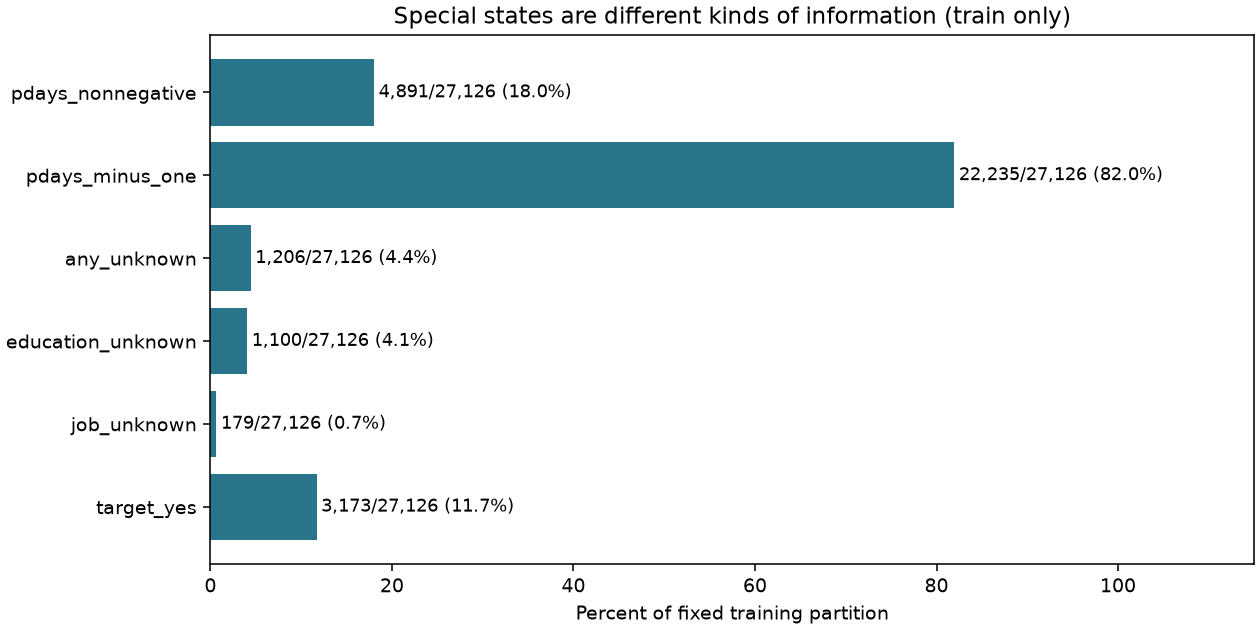

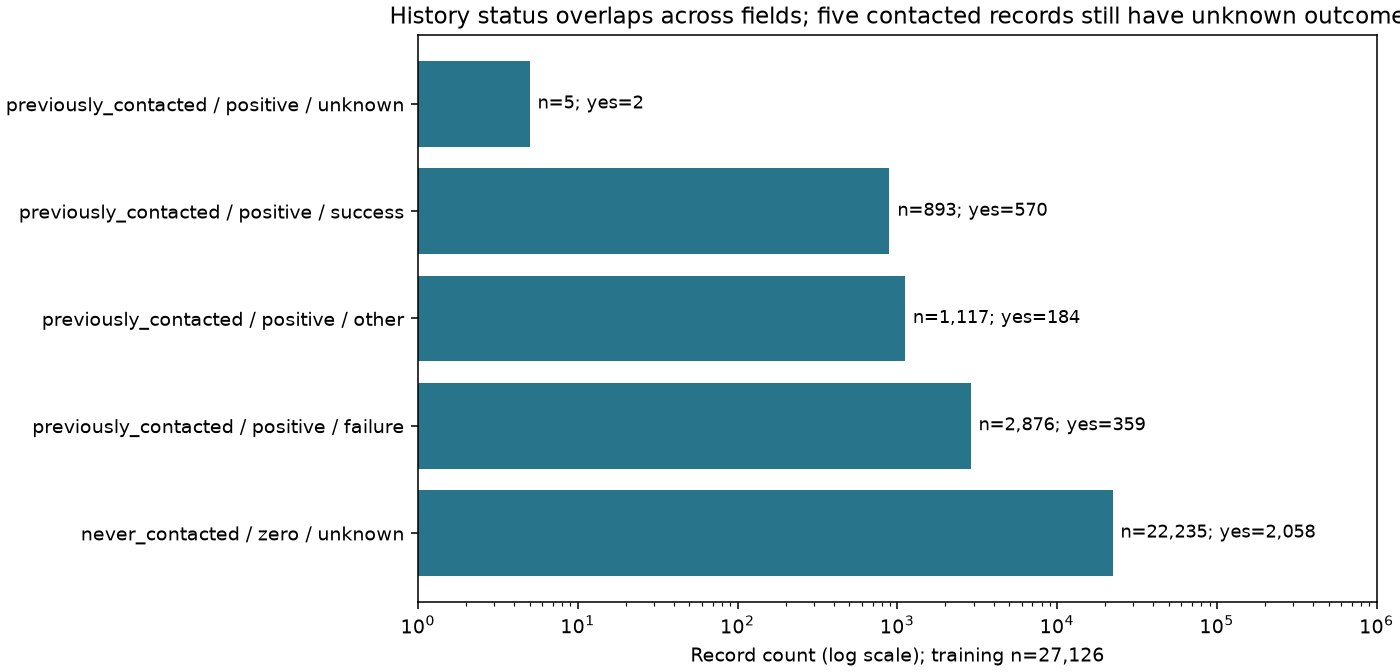

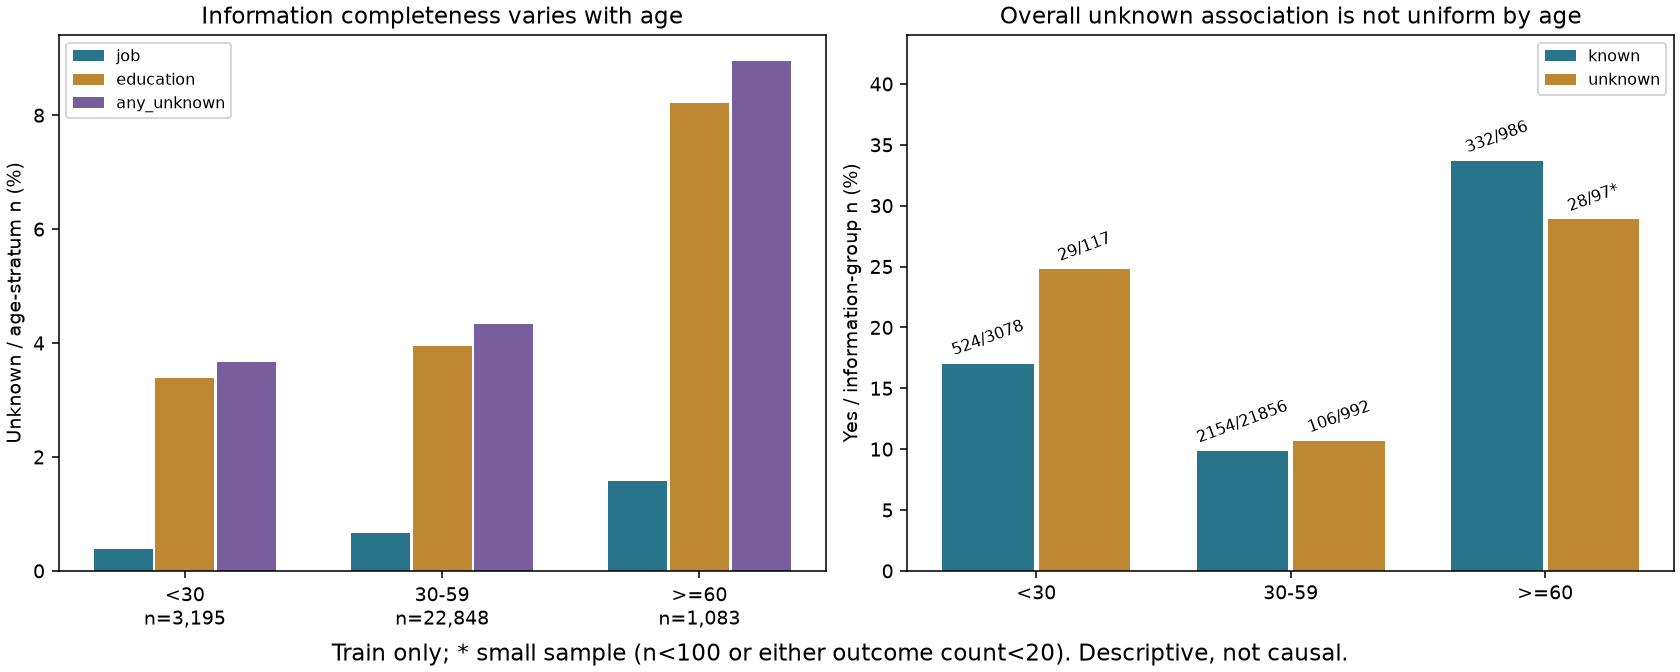

In [14]:
import tempfile
from IPython.display import Image, display
with tempfile.TemporaryDirectory() as folder:
    draw_figures(tables, folder)
    for path in sorted(Path(folder).glob("*.png")):
        display(Image(filename=str(path)))

## GenAI disclosure
OpenAI Codex assisted code, analysis, charts, narrative, and automated validation. Independent CSV reconstruction and frozen row alignment checks are in scripts/validate_b.py. Members must understand and personally verify the work; no human signature is implied.

## 04–05 / C: Formal preparation and D: Controlled evaluation

## 3. C formal pipeline / received and locally rerun

C code source is src/preprocessing.py. S separates the contact flag and conditional interval; the binary flag remains unscaled. U affects only job/education. Genuine missing values, invalid pdays and all-unknown mode-fit columns are rejected. C splits job/education from the remaining categorical block, so feature order differs from the historical D reference. Use its feature names to align coefficients. Both representations match exactly after canonical name alignment; see outputs/C/migration_comparison.csv. The current runs all use requirements.D.lock.txt, not a mixture of C and D environments.

In [15]:
"""C / D3: formal S/U pipeline; no partition is loaded here."""

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted


# FEATURES defined in the included A contract above

EXPERIMENTS = {"E0": (False, False), "ES": (True, False),
               "EU": (False, True), "ESU": (True, True)}
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]


class SemanticTransformer(TransformerMixin, BaseEstimator):
    """Check raw values and whitelist; preserve the index without learning parameters."""

    def __init__(self, use_s=False, use_u=False):
        self.use_s = use_s
        self.use_u = use_u

    def _prepare(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame with named raw columns")
        if X.columns.duplicated().any() or not set(FEATURES).issubset(X.columns):
            raise ValueError("Missing or duplicate input columns")
        frame = X.loc[:, FEATURES].copy(deep=True)
        # Actual missing values trigger STOP; imputation-related NaN appears after this check.
        if frame.isna().any().any():
            raise ValueError("STOP: actual missing values; ask A to verify raw data")
        for name in ["age", "balance", "pdays", "previous"]:
            if not pd.api.types.is_numeric_dtype(frame[name]) or not np.isfinite(frame[name]).all():
                raise ValueError(f"STOP: invalid numeric column {name}")
        if (frame.pdays < -1).any() or (frame.pdays % 1 != 0).any():
            raise ValueError("STOP: invalid pdays; expected -1 or nonnegative integer days")
        for name in CATEGORICAL:
            if not frame[name].map(lambda v: isinstance(v, str) and bool(v.strip())).all():
                raise ValueError(f"STOP: invalid category in {name}")
        if self.use_s:
            frame["has_previous_contact"] = (frame.pdays >= 0).astype("int64")
            frame["days_since_previous"] = frame.pdays.where(frame.pdays >= 0, 0)
            frame = frame.drop(columns="pdays")
        if not self.use_u:
            for name in ["job", "education"]:
                frame[name] = frame[name].astype(object).replace("unknown", np.nan)
        return frame

    def fit(self, X, y=None):
        frame = self._prepare(X)
        if not self.use_u and frame[["job", "education"]].isna().all().any():
            raise ValueError("STOP: no observed job/education mode in fit data")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.feature_names_out_ = np.asarray(frame.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, "feature_names_out_")
        return self._prepare(X)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_out_")
        return self.feature_names_out_.copy()


class MarketingPipeline(Pipeline):
    """Expose encoded feature names for the complete classifier pipeline."""

    def get_feature_names_out(self, input_features=None):
        steps = self.steps[:-1] if self.steps and self.steps[-1][0] == 'model' else self.steps
        return Pipeline(steps).get_feature_names_out(input_features)


def build_pipeline(use_s: bool, use_u: bool):
    """Return a fresh, unfitted pipeline for each independent training fit."""
    if type(use_s) is not bool or type(use_u) is not bool:
        raise TypeError("use_s and use_u must be bool")
    numeric = ["age", "balance", "previous", "days_since_previous" if use_s else "pdays"]
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    unknown_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop=None)),
    ])
    other_categories = [x for x in CATEGORICAL if x not in ["job", "education"]]
    transformers = [
        ("numeric", numeric_pipe, numeric),
        ("job_education", OneHotEncoder(handle_unknown="ignore", drop=None) if use_u else unknown_pipe,
         ["job", "education"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore", drop=None), other_categories),
    ]
    if use_s:
        transformers.append(("status", "passthrough", ["has_previous_contact"]))
    return MarketingPipeline([
        ("semantic", SemanticTransformer(use_s=use_s, use_u=use_u)),
        ("preprocess", ColumnTransformer(transformers, remainder="drop")),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                     class_weight=None, random_state=42)),
    ])


## 4. Unified metrics and original groups

AP is average precision, not trapezoidal PR-AUC. Brier=mean((p-y)^2). Recall=TP/(TP+FN), FPR=FP/(FP+TN), F1=2TP/(2TP+FP+FN). NaN means undefined denominator; AP is undefined without positives. Small sample: n<100 or positives<20 or negatives<20. Brier and FPR are lower-is-better. Recall changes multiplied by 100 are percentage points.

In [16]:
"""Shared evaluation, no model selection or holdout-dependent choices."""
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

EXPERIMENTS = {'E0': (False, False), 'ES': (True, False),
               'EU': (False, True), 'ESU': (True, True)}
THRESHOLD = 0.5
METRICS = ['AP', 'Recall', 'F1', 'Brier', 'Accuracy', 'FPR']
CONTRASTS = [('S_Uoff', 'ES', 'E0'), ('S_Uon', 'ESU', 'EU'),
             ('U_Soff', 'EU', 'E0'), ('U_Son', 'ESU', 'ES'),
             ('full', 'ESU', 'E0')]


def ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else float('nan')


def evaluate(y, probability):
    y = np.asarray(y)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not np.isin(y, [0, 1]).all():
        raise ValueError('Labels/probabilities must be aligned binary 1-D arrays')
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Non-finite or out-of-range probability')
    pred = p >= THRESHOLD
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    tn = int(((y == 0) & ~pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    n = len(y)
    return dict(n=n, n_positive=tp+fn, n_negative=tn+fp, TP=tp, FP=fp, TN=tn, FN=fn,
                AP=float(average_precision_score(y, p)) if tp+fn else float('nan'),
                Recall=ratio(tp, tp+fn), FPR=ratio(fp, fp+tn),
                Precision=ratio(tp, tp+fp), F1=ratio(2*tp, 2*tp+fp+fn),
                Brier=float(np.mean((p-y)**2)) if n else float('nan'),
                Accuracy=ratio(tp+tn, n), threshold=THRESHOLD)


def group_labels(X):
    # Raw pre-imputation information status, never recomputed from encoded features.
    age = pd.Series(np.where(X.age < 30, '<30', np.where(X.age < 60, '30-59', '>=60')), index=X.index)
    missing = X[['job', 'education']].eq('unknown').any(axis=1)
    return {'age': age, 'information': pd.Series(np.where(missing, 'any_unknown', 'both_known'), index=X.index)}


def subgroup_metrics(X, y, p, experiment):
    rows = []
    for dimension, labels in group_labels(X).items():
        levels = ['<30', '30-59', '>=60'] if dimension == 'age' else ['any_unknown', 'both_known']
        for label in levels:
            mask = labels.eq(label).to_numpy()
            row = evaluate(np.asarray(y)[mask], np.asarray(p)[mask])
            row.update(experiment=experiment, dimension=dimension, group=label,
                       small_sample=bool(row['n'] < 100 or row['n_positive'] < 20 or row['n_negative'] < 20))
            rows.append(row)
    return rows


def contrasts(table, group_columns=()):
    rows = []
    iterator = table.groupby(list(group_columns), sort=False) if group_columns else [((), table)]
    for keys, frame in iterator:
        keys = keys if isinstance(keys, tuple) else (keys,)
        indexed = frame.set_index('experiment')
        for effect, after, before in CONTRASTS:
            row = dict(zip(group_columns, keys))
            row.update(effect=effect, contrast=after+'-'+before)
            for metric in METRICS:
                row['delta_'+metric] = indexed.loc[after, metric] - indexed.loc[before, metric]
            if group_columns:
                row['n'] = int(indexed.loc[after, 'n'])
                row['small_sample'] = bool(indexed.loc[after, 'small_sample'])
            rows.append(row)
    return pd.DataFrame(rows)


## 5. Reproduce all four validation experiments

Only the 60% train partition is fitted. Each probability retains the exact frozen validation row_id order. Training contains 27,126 rows / 3,173 positives; validation contains 9,042 rows / 1,058 positives.

In [17]:
import warnings
from sklearn.exceptions import ConvergenceWarning
X_train, y_train = load_partition('train')
X_val, y_val = load_partition('val')
rows, group_rows, probability_frames, fitted = [], [], [], {}
for experiment, (s,u) in EXPERIMENTS.items():
    pipe = build_pipeline(s,u)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(X_train, y_train)
    probability = pipe.predict_proba(X_val)[:,1]
    rows.append(dict(experiment=experiment, **evaluate(y_val, probability)))
    group_rows.extend(subgroup_metrics(X_val,y_val,probability,experiment))
    probability_frames.append(pd.DataFrame({'row_id':X_val.index,'experiment':experiment,'y_true':y_val.to_numpy(),'probability':probability}))
    fitted[experiment] = pipe
validation = pd.DataFrame(rows)
subgroups = pd.DataFrame(group_rows)
probabilities = pd.concat(probability_frames, ignore_index=True)
expected = pd.read_csv(ROOT/'outputs/D/validation/metrics.csv')
np.testing.assert_allclose(validation[METRICS], expected[METRICS], rtol=1e-10, atol=1e-12)
display(validation[['experiment','n','n_positive','AP','Recall','F1','Brier','Accuracy','TP','FP','TN','FN']])


,experiment,n,n_positive,AP,Recall,F1,Brier,Accuracy,TP,FP,TN,FN
0,E0,9042,1058,0.358497,0.172968,0.277273,0.089328,0.894492,183,79,7905,875
1,ES,9042,1058,0.359485,0.172968,0.277273,0.089325,0.894492,183,79,7905,875
2,EU,9042,1058,0.358526,0.171078,0.274659,0.089337,0.894271,181,79,7905,877
3,ESU,9042,1058,0.359403,0.172023,0.275967,0.089333,0.894382,182,79,7905,876


## 6. References and all five contrasts

All-no accuracy is 88.299%, so roughly 89.4% model accuracy should not hide low positive recall. The constant training-prior probability is an extra no-feature probability reference.

In [18]:
reference_rows=[]
for label,p in [('all_no',0.),('training_prior',float(y_train.mean()))]:
    reference_rows.append(dict(reference=label, **evaluate(y_val,np.full(len(y_val),p))))
display(pd.DataFrame(reference_rows))
display(contrasts(validation))

,reference,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold
0,all_no,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.117010,0.88299,0.5
1,training_prior,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.103318,0.88299,0.5


,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR
0,S_Uoff,ES-E0,0.000987,0.000000,0.000000,-0.000003,0.000000,0.0
1,S_Uon,ESU-EU,0.000877,0.000945,0.001308,-0.000005,0.000111,0.0
2,U_Soff,EU-E0,0.000028,-0.001890,-0.002614,0.000009,-0.000221,0.0
3,U_Son,ESU-ES,-0.000082,-0.000945,-0.001306,0.000007,-0.000111,0.0
4,full,ESU-E0,0.000905,-0.000945,-0.001306,0.000005,-0.000111,0.0


## 7. Subgroup audit

Information groups use original job/education values. Each dimension partitions validation independently. Rows from age and information dimensions overlap and must not be added together.

In [19]:
display(subgroups[['experiment','dimension','group','n','n_positive','n_negative','TP','FP','TN','FN','Recall','FPR','Brier','small_sample']])
group_deltas=contrasts(subgroups,['dimension','group'])
display(group_deltas[group_deltas.effect.eq('full')])

,experiment,dimension,group,n,n_positive,n_negative,TP,FP,TN,FN,Recall,FPR,Brier,small_sample
0,E0,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131222,False
1,E0,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076871,False
2,E0,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225793,False
3,E0,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083210,False
4,E0,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089616,False
5,ES,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131258,False
6,ES,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076858,False
7,ES,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225897,False
8,ES,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083222,False
9,ES,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089613,False


,dimension,group,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR,n,small_sample
4,age,<30,full,ESU-E0,0.001520,0.000000,0.000000,-6.234996e-06,0.000000,0.0,1075,False
9,age,30-59,full,ESU-E0,0.001622,0.000000,0.000000,-7.425374e-07,0.000000,0.0,7603,False
14,age,>=60,full,ESU-E0,-0.001322,-0.007812,-0.009862,1.493454e-04,-0.002747,0.0,364,False
19,information,any_unknown,full,ESU-E0,0.001488,0.000000,0.000000,1.229313e-04,0.000000,0.0,407,False
24,information,both_known,full,ESU-E0,0.000712,-0.000988,-0.001372,-9.287144e-07,-0.000116,0.0,8635,False


## 8. Evidence charts (generated from reproduced values)

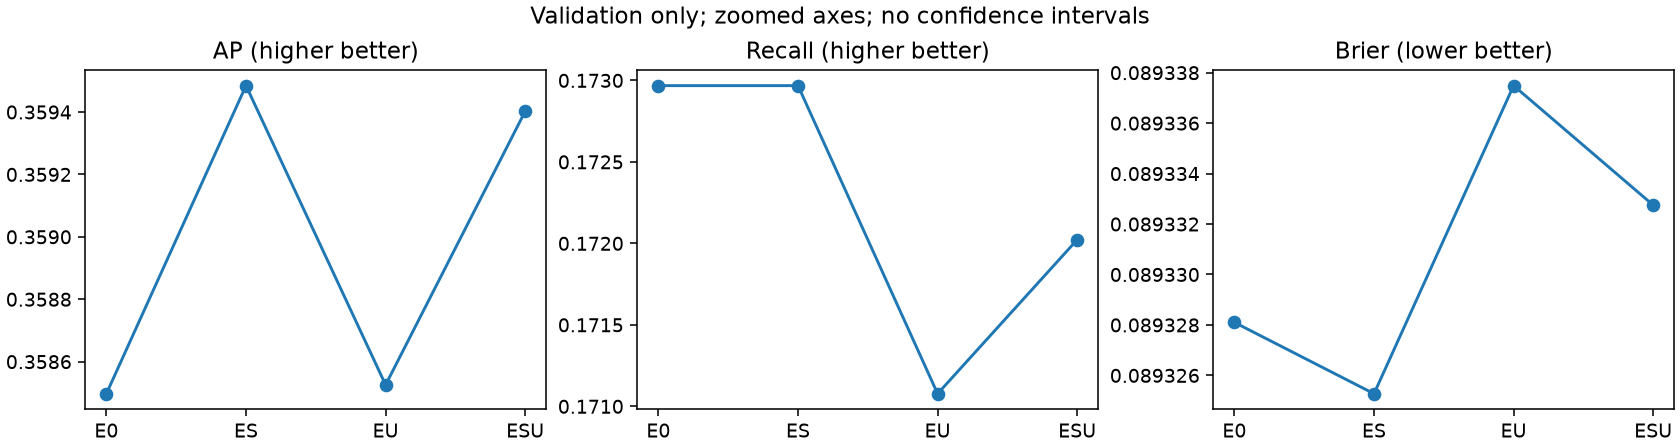

In [20]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,3,figsize=(12,3.2),layout='constrained')
for ax,metric in zip(axes,['AP','Recall','Brier']):
    ax.plot(validation.experiment,validation[metric],marker='o')
    ax.set_title(metric+(' (lower better)' if metric=='Brier' else ' (higher better)'))
    ax.ticklabel_format(axis='y',style='plain',useOffset=False)
fig.suptitle('Validation only; zoomed axes; no confidence intervals')
from io import BytesIO
from IPython.display import Image
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=140)
display(Image(data=buffer.getvalue()))
plt.close(fig)


## 05b / Final test: Saved predictions and complete metrics

The following code recalculates metrics from the predictions produced after the original freeze, checking hashes, row order and labels. It does not refit final-test models or use test results to develop a new strategy. This is reproducible metric replay; model fitting is reproduced on validation in the preceding section.

,experiment,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold
0,E0,9043,1058,7985,177,83,7902,881,0.347165,0.167297,0.010394,0.680769,0.268589,0.090018,0.893398,0.5
1,ES,9043,1058,7985,178,83,7902,880,0.347626,0.168242,0.010394,0.681992,0.269901,0.090013,0.893509,0.5
2,EU,9043,1058,7985,176,83,7902,882,0.346853,0.166352,0.010394,0.679537,0.267274,0.090029,0.893288,0.5
3,ESU,9043,1058,7985,176,83,7902,882,0.346903,0.166352,0.010394,0.679537,0.267274,0.090022,0.893288,0.5


,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR
0,S_Uoff,ES-E0,0.000461,0.000945,0.001313,-0.000005,0.000111,0.0
1,S_Uon,ESU-EU,0.000050,0.000000,0.000000,-0.000007,0.000000,0.0
2,U_Soff,EU-E0,-0.000312,-0.000945,-0.001315,0.000011,-0.000111,0.0
3,U_Son,ESU-ES,-0.000723,-0.001890,-0.002627,0.000009,-0.000221,0.0
4,full,ESU-E0,-0.000262,-0.000945,-0.001315,0.000004,-0.000111,0.0


,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold,experiment,dimension,group,small_sample
0,1003,179,824,31,11,813,148,0.421496,0.173184,0.013350,0.738095,0.280543,0.128798,0.841476,0.5,E0,age,<30,False
1,7703,767,6936,116,57,6879,651,0.303426,0.151239,0.008218,0.670520,0.246809,0.079635,0.908088,0.5,E0,age,30-59,False
2,337,112,225,30,15,210,82,0.511308,0.267857,0.066667,0.666667,0.382166,0.211922,0.712166,0.5,E0,age,>=60,False
3,405,59,346,10,3,343,49,0.457936,0.169492,0.008671,0.769231,0.277778,0.104296,0.871605,0.5,E0,information,any_unknown,False
4,8638,999,7639,167,80,7559,832,0.342042,0.167167,0.010473,0.676113,0.268058,0.089348,0.894420,0.5,E0,information,both_known,False
5,1003,179,824,31,11,813,148,0.421664,0.173184,0.013350,0.738095,0.280543,0.128750,0.841476,0.5,ES,age,<30,False
6,7703,767,6936,117,57,6879,650,0.303845,0.152542,0.008218,0.672414,0.248672,0.079633,0.908218,0.5,ES,age,30-59,False
7,337,112,225,30,15,210,82,0.511704,0.267857,0.066667,0.666667,0.382166,0.211979,0.712166,0.5,ES,age,>=60,False
8,405,59,346,10,3,343,49,0.456047,0.169492,0.008671,0.769231,0.277778,0.104303,0.871605,0.5,ES,information,any_unknown,False
9,8638,999,7639,168,80,7559,831,0.342525,0.168168,0.010473,0.677419,0.269447,0.089343,0.894536,0.5,ES,information,both_known,False


,dimension,group,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR,n,small_sample
0,age,<30,S_Uoff,ES-E0,0.000168,0.000000,0.000000,-4.783452e-05,0.000000,0.0,1003,False
1,age,<30,S_Uon,ESU-EU,0.000297,0.000000,0.000000,-5.419004e-05,0.000000,0.0,1003,False
2,age,<30,U_Soff,EU-E0,-0.000807,0.000000,0.000000,4.548152e-05,0.000000,0.0,1003,False
3,age,<30,U_Son,ESU-ES,-0.000678,0.000000,0.000000,3.912600e-05,0.000000,0.0,1003,False
4,age,<30,full,ESU-E0,-0.000510,0.000000,0.000000,-8.708522e-06,0.000000,0.0,1003,False
5,age,30-59,S_Uoff,ES-E0,0.000419,0.001304,0.001863,-2.120905e-06,0.000130,0.0,7703,False
6,age,30-59,S_Uon,ESU-EU,0.000436,0.000000,0.000000,2.103146e-08,0.000000,0.0,7703,False
7,age,30-59,U_Soff,EU-E0,-0.000051,0.000000,0.000000,1.131179e-06,0.000000,0.0,7703,False
8,age,30-59,U_Son,ESU-ES,-0.000034,-0.001304,-0.001863,3.273116e-06,-0.000130,0.0,7703,False
9,age,30-59,full,ESU-E0,0.000385,0.000000,0.000000,1.152211e-06,0.000000,0.0,7703,False


,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold,reference,fit_n,probability
0,9043,1058,7985,0,0,7985,1058,0.116997,0.0,0.0,NaN,0.0,0.116997,0.883003,0.5,all_no,36168,0.000000
1,9043,1058,7985,0,0,7985,1058,0.116997,0.0,0.0,NaN,0.0,0.103308,0.883003,0.5,training_prior,36168,0.116982


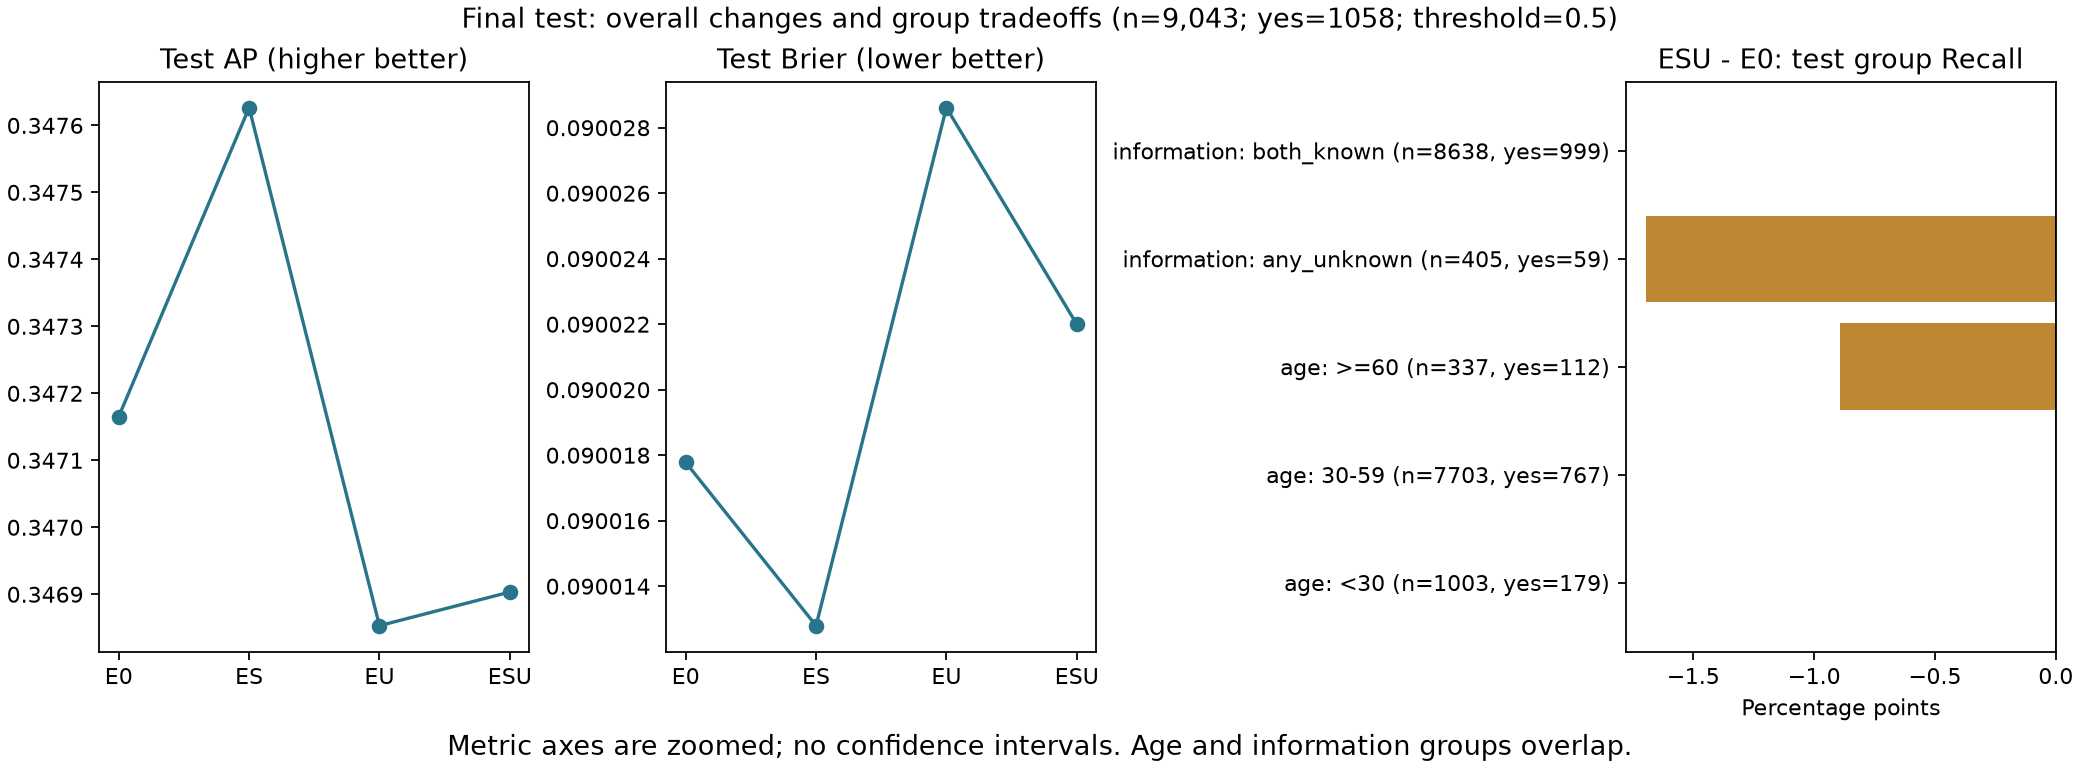

In [21]:
import hashlib
frozen = json.loads((ROOT/'outputs/D/freeze.json').read_text())
completed = json.loads((ROOT/'outputs/D/test_completed.json').read_text())
assert completed['freeze_sha256'] == hashlib.sha256((ROOT/'outputs/D/freeze.json').read_bytes()).hexdigest()
for name, expected in completed['test_hashes'].items():
    assert hashlib.sha256((ROOT/'outputs/D/test'/name).read_bytes()).hexdigest() == expected, name
for rel, expected in frozen['fingerprint']['files'].items():
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest() == expected, rel
for rel, expected in frozen['evidence_hashes'].items():
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest() == expected, rel
for name, expected in frozen['validation_hashes'].items():
    assert hashlib.sha256((ROOT/'outputs/D/validation'/name).read_bytes()).hexdigest() == expected, name
prediction_table = pd.read_csv(ROOT/'outputs/D/test/predictions.csv',float_precision='round_trip')
saved_test = pd.read_csv(ROOT/'outputs/D/test/metrics.csv')
X_holdout, y_holdout = load_partition('test', allow_test=True)
test_rows, test_group_rows = [], []
for experiment, pred in prediction_table.groupby('experiment',sort=False):
    assert pred.row_id.tolist() == y_holdout.index.tolist()
    assert pred.y_true.tolist() == y_holdout.tolist()
    assert pred.prediction.tolist() == (pred.probability >= .5).astype(int).tolist()
    metrics = evaluate(pred.y_true,pred.probability)
    saved = saved_test.set_index('experiment').loc[experiment]
    for key,value in metrics.items():
        np.testing.assert_allclose(value,saved[key],atol=1e-12,rtol=0,equal_nan=True)
    test_rows.append(dict(experiment=experiment,**metrics))
    test_group_rows.extend(subgroup_metrics(X_holdout,y_holdout,pred.probability.to_numpy(),experiment))
final_metrics = pd.DataFrame(test_rows)
final_groups = pd.DataFrame(test_group_rows)
pd.testing.assert_frame_equal(final_groups,pd.read_csv(ROOT/'outputs/D/test/subgroups.csv'),check_exact=False,atol=1e-12)
pd.testing.assert_frame_equal(contrasts(final_metrics),pd.read_csv(ROOT/'outputs/D/test/contrasts.csv'),check_exact=False,atol=1e-12)
pd.testing.assert_frame_equal(contrasts(final_groups,['dimension','group']),pd.read_csv(ROOT/'outputs/D/test/subgroup_contrasts.csv'),check_exact=False,atol=1e-12)
display(final_metrics)
display(contrasts(final_metrics))
display(final_groups)
display(contrasts(final_groups,['dimension','group']))
display(pd.read_csv(ROOT/'outputs/D/test/references.csv'))
from IPython.display import Image
display(Image(filename=str(ROOT/'outputs/B/figures/04_model_tradeoffs.png')))


## 06 / Discussion and limitations

Training supports B's EDA and validation fitting; validation supports the predefined comparisons. After freezing, each of the four models was refitted on train+validation (36,168 rows) and evaluated on 9,043 fixed test rows. No hyperparameter or threshold search was performed, and the whitelist and groups remained fixed. The companion run manifest records the environment, iterations and hashes. Computational authorization is distinct from human sign-off.

### Validation: fit on training, evaluate on validation

| experiment | n | n_positive | AP | Recall | F1 | Brier | Accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- |
| E0 | 9042 | 1058 | 0.358497 | 0.172968 | 0.277273 | 0.0893281 | 0.894492 |
| ES | 9042 | 1058 | 0.359485 | 0.172968 | 0.277273 | 0.0893253 | 0.894492 |
| EU | 9042 | 1058 | 0.358526 | 0.171078 | 0.274659 | 0.0893375 | 0.894271 |
| ESU | 9042 | 1058 | 0.359403 | 0.172023 | 0.275967 | 0.0893327 | 0.894382 |

### Final test: original fit on train+validation, evaluate on test

| experiment | n | n_positive | TP | FP | TN | FN | AP | Recall | F1 | Brier | Accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| E0 | 9043 | 1058 | 177 | 83 | 7902 | 881 | 0.347165 | 0.167297 | 0.268589 | 0.0900178 | 0.893398 |
| ES | 9043 | 1058 | 178 | 83 | 7902 | 880 | 0.347626 | 0.168242 | 0.269901 | 0.0900128 | 0.893509 |
| EU | 9043 | 1058 | 176 | 83 | 7902 | 882 | 0.346853 | 0.166352 | 0.267274 | 0.0900286 | 0.893288 |
| ESU | 9043 | 1058 | 176 | 83 | 7902 | 882 | 0.346903 | 0.166352 | 0.267274 | 0.090022 | 0.893288 |

### All five contrasts: raw score differences

| effect | contrast | delta_AP | delta_Recall | delta_F1 | delta_Brier | delta_Accuracy | delta_FPR |
| --- | --- | --- | --- | --- | --- | --- | --- |
| S_Uoff | ES-E0 | 0.000461116 | 0.00094518 | 0.00131267 | -4.98461e-06 | 0.000110583 | 0 |
| S_Uon | ESU-EU | 5.02483e-05 | 0 | 0 | -6.61145e-06 | 0 | 0 |
| U_Soff | EU-E0 | -0.000312254 | -0.00094518 | -0.00131466 | 1.08335e-05 | -0.000110583 | 0 |
| U_Son | ESU-ES | -0.000723122 | -0.00189036 | -0.00262733 | 9.20666e-06 | -0.000221166 | 0 |
| full | ESU-E0 | -0.000262006 | -0.00094518 | -0.00131466 | 4.22205e-06 | -0.000110583 | 0 |

For the full preparation, ESU-E0 changes AP by -0.00026201, Recall by -0.0945 percentage points, F1 by -0.00131466 and Brier by +0.00000422. Lower Brier/FPR and higher AP/Recall/F1 are preferable. Deterioration and ties are retained. No significance test supports a claim of statistically significant improvement.

Assess S through both ES-E0 and ESU-EU, and U through EU-E0 and ESU-ES. Overlapping history signals offer a possible explanation for small changes, not proof of mechanism. Unknown states have age-dependent associations, without guaranteeing benefits in every group. S/U alter representation, dimensionality and regularization. Their score differences are not causal effects, and validation-to-test changes also involve different fitting sample sizes.

On this test set, S slightly improves AP and Brier with either U setting, but identifies one additional positive only when U is off. U lowers AP and Recall and raises Brier with either S setting. Retaining unknown information was a reason to test U, not a demonstrated benefit: this model does not show that benefit. This does not imply that mode imputation is universally better.

### Full-preparation contrasts within groups

| dimension | group | effect | contrast | delta_AP | delta_Recall | delta_F1 | delta_Brier | delta_Accuracy | delta_FPR | n | small_sample |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| age | <30 | full | ESU-E0 | -0.000509697 | 0 | 0 | -8.70852e-06 | 0 | 0 | 1003 | False |
| age | 30-59 | full | ESU-E0 | 0.000384591 | 0 | 0 | 1.15221e-06 | 0 | 0 | 7703 | False |
| age | >=60 | full | ESU-E0 | -0.000798208 | -0.00892857 | -0.0103707 | 0.000112876 | -0.00296736 | 0 | 337 | False |
| information | any_unknown | full | ESU-E0 | -0.00417009 | -0.0169492 | -0.0242567 | 0.00016632 | -0.00246914 | 0 | 405 | False |
| information | both_known | full | ESU-E0 | -5.67293e-05 | 0 | 0 | -3.37804e-06 | 0 | 0 | 8638 | False |

The preceding executable results include group denominators, positive/negative counts, confusion matrices, all four models and all five contrasts. Information groups use original values. A group is flagged as small when n<100 or either class has fewer than 20 observations. Age and information dimensions overlap and must not be added together. Descriptive group differences are not proof of discrimination or fairness.

Relative to baseline, full preparation reduces Recall from 30/112 to 29/112 for age >=60 (-0.8929 percentage points), and from 10/59 to 9/59 for original unknown information (-1.6949 points). Brier also rises in these groups. Overlap means these changes cannot be added as two distinct missed people. A small aggregate change can hide a larger group-level cost.

### No-feature references and limitations

| reference | n | AP | Recall | F1 | Brier | Accuracy | probability |
| --- | --- | --- | --- | --- | --- | --- | --- |
| all_no | 9043 | 0.116997 | 0 | 0 | 0.116997 | 0.883003 | 0 |
| training_prior | 9043 | 0.116997 | 0 | 0 | 0.103308 | 0.883003 | 0.116982 |

Compare accuracy with the all-no reference and consider low positive Recall. AP measures ranking and is not trapezoidal PR-AUC. Brier reflects both discrimination and calibration, not a standalone calibration test. Without customer IDs, complete snapshot timing or randomized marketing assignment, we cannot establish customer independence, future generalization, causal call effects or actual profit. Retained numerical tails may affect the linear model. GenAI assistance and pending personal review must remain disclosed.

## Contributions, GenAI disclosure and remaining work

**A — Yu Qiushi:** source provenance, governance, original audit and frozen splits. **B — Chen Junyu:** training-only findings, independent count verification, stratified evidence, figures and narrative with Codex assistance. **C — Sun Shaojie:** the supplied formal S/U pipeline and transformation tests. **D — Liang Shuang:** unified evaluation and the original delivered evaluation package.

At the task owner's request, OpenAI Codex assisted C/D integration, B implementation, environment verification, authorized frozen-test execution, final Notebook assembly and English presentation materials. These additions are not represented as personal work performed or reviewed by C or D.

**GenAI disclosure:** OpenAI Codex assisted coding, debugging, analysis suggestions, charts, explanation drafts, translation and automated verification. Checks include independent raw-CSV counts, hashes and frozen partitions, transformation and leakage tests, prediction-level metric reconstruction, and execution in a fresh kernel. Automated checks do not constitute personal understanding or signatures. All members must review and be able to explain the submitted work.

Member names have been supplied. Remaining items are the group number, actual member review, a continuous four-person video within 12 minutes, its public link, NTULearn submission and peer assessment. Data attribution and CC BY 4.0 licensing are retained above and in the companion source notices.